In [3]:
# TODO:
"""
🚀 Neden Bu Mimari Çok Başarılı?
Güvenlik Katmanlaşması:

Model A (0.8+): Senin "Altın Standardın". En yüksek hassasiyete sahip. Kimlik doğrulama için kullanılacak ana model.

Model B (0.5 - 0.8): "Esnek Model". Gürültüyü tolere edebilen, ancak Model A kadar keskin olmayan ara model.

Model C (0.5-): Bu grup bir "Eğitim seti" değil, bir "Reddetme Seti" olmalı. Bu seviyedeki sinyalleri eğitmek, sistemi yanıltmaya (false acceptance) neden olabilir.

Jüriyi Büyüleyecek "Akıllı Geçiş" Mekanizması:
Sistemine bir "Decision Engine" (Karar Mekanizması) ekleyebilirsin:

Kullanıcı EKG'sini gönderdi.

Önce nk.ecg_quality() çalışır.

Skor 0.8'den büyükse Model A'ya yönlendirilir.

Skor 0.5 - 0.8 arasındaysa Model B'ye yönlendirilir.

Skor 0.5'ten düşükse sistem kullanıcıya "Sinyal çok zayıf, lütfen saatini sıkılaştır ve hareketsiz kal" uyarısı verir.

🛠️ İzleyeceğin Yol Haritası
Bu mimariyi kurmak için şu modüler adımları takip etmelisin:

Veri Kümeleme (Data Partitioning):
02_preprocessing_and_pairs.ipynb notebook'unda veriyi tüm sinyallerin kalite skorlarını hesaplayarak şu üç klasöre ayır:

/data/train/high_quality/

/data/train/medium_quality/

/data/train/low_quality/ (Bunu eğitime alma, sadece test için sakla)

Siyam Ağlarını Eğitme:

Eğitim 1: Model A'yı sadece high_quality çiftleriyle eğit.

Eğitim 2: Model B'yi hem high_quality hem de medium_quality karışımıyla (Fine-tuning yaparak) eğit.

Performans Kıyaslaması:
Jüriye şunu göstereceksin: "Model A, yüksek kaliteli veride %99 doğruluk veriyor; Model B ise orta kaliteli veride %92 doğrulukla güvenliği korumaya devam ediyor."

"""

'\n🚀 Neden Bu Mimari Çok Başarılı?\nGüvenlik Katmanlaşması:\n\nModel A (0.8+): Senin "Altın Standardın". En yüksek hassasiyete sahip. Kimlik doğrulama için kullanılacak ana model.\n\nModel B (0.5 - 0.8): "Esnek Model". Gürültüyü tolere edebilen, ancak Model A kadar keskin olmayan ara model.\n\nModel C (0.5-): Bu grup bir "Eğitim seti" değil, bir "Reddetme Seti" olmalı. Bu seviyedeki sinyalleri eğitmek, sistemi yanıltmaya (false acceptance) neden olabilir.\n\nJüriyi Büyüleyecek "Akıllı Geçiş" Mekanizması:\nSistemine bir "Decision Engine" (Karar Mekanizması) ekleyebilirsin:\n\nKullanıcı EKG\'sini gönderdi.\n\nÖnce nk.ecg_quality() çalışır.\n\nSkor 0.8\'den büyükse Model A\'ya yönlendirilir.\n\nSkor 0.5 - 0.8 arasındaysa Model B\'ye yönlendirilir.\n\nSkor 0.5\'ten düşükse sistem kullanıcıya "Sinyal çok zayıf, lütfen saatini sıkılaştır ve hareketsiz kal" uyarısı verir.\n\n🛠️ İzleyeceğin Yol Haritası\nBu mimariyi kurmak için şu modüler adımları takip etmelisin:\n\nVeri Kümeleme (Data Partit

In [4]:
!pip install wfdb neurokit2 tqdm

In [5]:
# Sistem ve Dosya Yönetimi
import os
import sys

# Veri Manipülasyonu ve Matematiksel İşlemler
import numpy as np
import pandas as pd

# Sinyal İşleme (EKG Temizleme ve Analiz)
import wfdb
import neurokit2 as nk
import scipy.signal as signal

# İlerleme Çubuğu (Uzun döngüleri takip etmek için)
from tqdm import tqdm

# Görselleştirme (Ara kontroller için)
import matplotlib.pyplot as plt
import seaborn as sns

import itertools

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
drive_base_path = '/content/drive/MyDrive/BeatKrypt/'
data_path = os.path.join(drive_base_path)
csv_path = os.path.join(data_path, 'ptbxl_database.csv')

# Örnekleme frekansı (Edge AI hedefi için)
sample_rate = 100

print(f"✓ Veri seti yolu: {csv_path}")

✓ Veri seti yolu: /content/drive/MyDrive/BeatKrypt/ptbxl_database.csv


In [8]:
ptbxl = pd.read_csv(csv_path)

In [9]:
# Her hastanın kaç kaydı olduğunu sayalım
patient_record_counts = ptbxl['patient_id'].value_counts().reset_index()
patient_record_counts.columns = ['patient_id', 'record_count']

# 3 veya daha fazla kaydı olan hastaları filtreleyelim
positive_patient_ids_df = patient_record_counts[patient_record_counts['record_count'] >= 3]

# Pozitif Çift Havuzu: 3 veya daha fazla kaydı olan hastaların ID'leri
positive_pair_patient_ids = positive_patient_ids_df['patient_id'].tolist()

# Negatif Çift Havuzu: Tüm benzersiz hasta ID'leri
negative_pair_patient_ids = ptbxl['patient_id'].unique().tolist()

print(f"Pozitif Çift Havuzu için Hasta ID sayısı: {len(positive_pair_patient_ids)}")
print(f"Negatif Çift Havuzu için Hasta ID sayısı: {len(negative_pair_patient_ids)}")

Pozitif Çift Havuzu için Hasta ID sayısı: 521
Negatif Çift Havuzu için Hasta ID sayısı: 18869


In [10]:
output_dir = os.path.join(drive_base_path, 'processed_data')
os.makedirs(output_dir, exist_ok=True)
print(f"✓ Çıktı dizini oluşturuldu: {output_dir}")

✓ Çıktı dizini oluşturuldu: /content/drive/MyDrive/BeatKrypt/processed_data


In [11]:
positive_pairs = []

# Sadece pozitif havuzdaki (3+ kaydı olan) hastaların verilerini filtrele
pure_positives_df = ptbxl[ptbxl['patient_id'].isin(positive_pair_patient_ids)]

# Her bir pozitif hasta için döngü
for patient_id in tqdm(positive_pair_patient_ids, desc="Pozitif Çiftler Oluşturuluyor"):
    # Bu hastaya ait tüm kayıtların dosya adlarını al
    patient_records = pure_positives_df[pure_positives_df['patient_id'] == patient_id]['filename_hr'].tolist()

    # Hastanın kayıtları arasındaki tüm benzersiz ikili kombinasyonları oluştur (Örn: C(4,2) = 6 çift)
    for rec1, rec2 in itertools.combinations(patient_records, 2):
        positive_pairs.append({
            'left_filename': rec1,
            'right_filename': rec2,
            'label': 1.0  # Aynı insan
        })

positive_pairs_df = pd.DataFrame(positive_pairs)
total_positive_count = len(positive_pairs_df)
print(f"\n✓ Toplam oluşturulan pozitif çift sayısı: {total_positive_count}")

Pozitif Çiftler Oluşturuluyor: 100%|██████████| 521/521 [00:00<00:00, 2737.04it/s]



✓ Toplam oluşturulan pozitif çift sayısı: 2684


In [12]:
negative_pairs = []

# Sadece negatif havuzdaki (3'ten az kaydı olan) hastaların verilerini filtrele
pure_negatives_df = ptbxl[ptbxl['patient_id'].isin(negative_pair_patient_ids)]

# Hedef sayımız artık pozitif çift sayısına tam olarak eşit
target_negative_count = total_positive_count  # 2684 çift

for _ in tqdm(range(target_negative_count), desc="Dengeli Negatif Çiftler Oluşturuluyor"):

    # 1. Negatif havuzdan rastgele ilk hastayı seç
    row_left = pure_negatives_df.sample(n=1).iloc[0]
    patient_left = row_left['patient_id']

    # 2. Karşı tarafa KESİNLİKLE aynı hastanın denk gelmesini engelle
    row_right = pure_negatives_df[pure_negatives_df['patient_id'] != patient_left].sample(n=1).iloc[0]

    negative_pairs.append({
        'left_filename': row_left['filename_hr'],
        'right_filename': row_right['filename_hr'],
        'label': 0.0  # Farklı insanlar
    })

negative_pairs_df = pd.DataFrame(negative_pairs)
print(f"\n✓ Toplam oluşturulan negatif çift sayısı: {len(negative_pairs_df)}")

Dengeli Negatif Çiftler Oluşturuluyor: 100%|██████████| 2684/2684 [00:34<00:00, 78.01it/s] 


✓ Toplam oluşturulan negatif çift sayısı: 2684


In [13]:
# 1. İki havuzu tek bir büyük DataFrame'de birleştir
all_pairs_df = pd.concat([positive_pairs_df, negative_pairs_df], ignore_index=True)

# 2. Satırları rastgele karıştır (frac=1 tüm veriyi al demek, random_state=42 ise tekrarlanabilirlik sağlar)
all_pairs_df = all_pairs_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 3. Sonuçları doğrula
print(f"✓ Eşleştirme tablosu başarıyla birleştirildi ve karıştırıldı!")
print(f"Toplam Çift Sayısı: {len(all_pairs_df)}")
print(f"\nSınıf Dağılımı:\n{all_pairs_df['label'].value_counts()}")

# İlk 5 satıra göz atalım, 1.0 ve 0.0 etiketleri karışık gelmeli
all_pairs_df.head()

✓ Eşleştirme tablosu başarıyla birleştirildi ve karıştırıldı!
Toplam Çift Sayısı: 5368

Sınıf Dağılımı:
label
1.0    2684
0.0    2684
Name: count, dtype: int64


,left_filename,right_filename,label
0,records500/04000/04859_hr,records500/05000/05166_hr,1.0
1,records500/14000/14019_hr,records500/15000/15335_hr,0.0
2,records500/11000/11413_hr,records500/11000/11481_hr,1.0
3,records500/10000/10259_hr,records500/17000/17605_hr,0.0
4,records500/04000/04041_hr,records500/12000/12214_hr,0.0


In [14]:
# Dosya yollarını records500'den records100'e çeviriyoruz
all_pairs_df['left_filename'] = all_pairs_df['left_filename'].str.replace('records500', 'records100')
all_pairs_df['right_filename'] = all_pairs_df['right_filename'].str.replace('records500', 'records100')

# Ayrıca sonundaki '_hr' takısını, 100Hz standartına uygun olması için '_lr' yapıyoruz (eğer PTB-XL klasör yapın bu şekildeyse)
all_pairs_df['left_filename'] = all_pairs_df['left_filename'].str.replace('_hr', '_lr')
all_pairs_df['right_filename'] = all_pairs_df['right_filename'].str.replace('_hr', '_lr')

print("✓ Dosya yolları 100 Hz (records100) olarak güncellendi!")
all_pairs_df.sample(5)

✓ Dosya yolları 100 Hz (records100) olarak güncellendi!


,left_filename,right_filename,label
2543,records100/04000/04382_lr,records100/05000/05772_lr,1.0
3955,records100/20000/20603_lr,records100/21000/21017_lr,1.0
3829,records100/15000/15599_lr,records100/15000/15618_lr,1.0
1067,records100/16000/16204_lr,records100/16000/16620_lr,0.0
4086,records100/15000/15117_lr,records100/13000/13983_lr,0.0


In [15]:
# Drive'daki hantal ağ okumasından kurtulmak için klasörü yerele kopyalıyoruz
!cp -r /content/drive/MyDrive/BeatKrypt/records100/content/records100_local
print("✓ Kopyalama tamamlandı! İşlemler yerel diskten jet hızıyla yapılacak.")

cp: missing destination file operand after '/content/drive/MyDrive/BeatKrypt/records100/content/records100_local'
Try 'cp --help' for more information.
✓ Kopyalama tamamlandı! İşlemler yerel diskten jet hızıyla yapılacak.


In [16]:
# Okumayı doğrudan kopyaladığımız yerel klasörden yapıyoruz
BASE_DIR = "/content/records100_local/"

X_left = []
X_right = []
y = []

skipped_low_variance = 0
skipped_no_peaks = 0
successful_pairs = 0

for idx, row in tqdm(all_pairs_df.iterrows(), total=len(all_pairs_df), desc="Sinyaller İşleniyor"):
    try:
        # Yol uyuşmazlığını temizliyoruz
        left_rel = row['left_filename'].replace('records100/', '')
        right_rel = row['right_filename'].replace('records100/', '')

        left_path = os.path.join(BASE_DIR, left_rel)
        right_path = os.path.join(BASE_DIR, right_rel)

        # Sinyal Okuma
        signal_left, _ = wfdb.rdsamp(left_path, channels=[0])
        signal_right, _ = wfdb.rdsamp(right_path, channels=[0])

        signal_left = signal_left.flatten()
        signal_right = signal_right.flatten()

        # Temizleme
        clean_left = nk.ecg_clean(signal_left, sampling_rate=100, method="neurokit")
        clean_right = nk.ecg_clean(signal_right, sampling_rate=100, method="neurokit")

        # Varyans Kontrolü
        if np.std(clean_left) < 0.01 or np.std(clean_right) < 0.01:
            skipped_low_variance += 1
            continue

        # R-Tepe Bulma
        _, info_left = nk.ecg_peaks(clean_left, sampling_rate=100, method="neurokit")
        _, info_right = nk.ecg_peaks(clean_right, sampling_rate=100, method="neurokit")

        peaks_left = info_left["ECG_R_Peaks"]
        peaks_right = info_right["ECG_R_Peaks"]

        if len(peaks_left) == 0 or len(peaks_right) == 0:
            skipped_no_peaks += 1
            continue

        # Hizalama Kontrolü
        idx_l = next((p for p in peaks_left if 30 <= p < len(clean_left) - 50), None)
        idx_r = next((p for p in peaks_right if 30 <= p < len(clean_right) - 50), None)

        if idx_l is None or idx_r is None:
            skipped_no_peaks += 1
            continue

        # Dilimleme
        slice_left = clean_left[idx_l - 30 : idx_l + 50]
        slice_right = clean_right[idx_r - 30 : idx_r + 50]

        # Normalizasyon
        norm_left = (slice_left - np.min(slice_left)) / (np.max(slice_left) - np.min(slice_left) + 1e-8)
        norm_right = (slice_right - np.min(slice_right)) / (np.max(slice_right) - np.min(slice_right) + 1e-8)

        X_left.append(norm_left)
        X_right.append(norm_right)
        y.append(row['label'])

        successful_pairs += 1

    except Exception:
        continue

print(f"\n✓ Döngü Tamamlandı!")
print(f"Başarıyla İşlenen Çift Sayısı: {successful_pairs}")
print(f"Düşük Varyans Nedeniyle Elenen: {skipped_low_variance}")
print(f"R-Tepe Hatası Nedeniyle Elenen: {skipped_no_peaks}")

Sinyaller İşleniyor: 100%|██████████| 5368/5368 [00:00<00:00, 6333.91it/s]


✓ Döngü Tamamlandı!
Başarıyla İşlenen Çift Sayısı: 1
Düşük Varyans Nedeniyle Elenen: 0
R-Tepe Hatası Nedeniyle Elenen: 0


In [17]:
X_left_np = np.array(X_left, dtype=np.float32)
X_right_np = np.array(X_right, dtype=np.float32)
y_np = np.array(y, dtype=np.float32)

OUTPUT_DIR = "/content/drive/MyDrive/BeatKrypt/processed_data/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.save(os.path.join(OUTPUT_DIR, "X_left.npy"), X_left_np)
np.save(os.path.join(OUTPUT_DIR, "X_right.npy"), X_right_np)
np.save(os.path.join(OUTPUT_DIR, "y.npy"), y_np)

print("=== DEPOLAMA RAPORU ===")
print(f"X_left Boyutu: {X_left_np.shape}")
print(f"X_right Boyutu: {X_right_np.shape}")
print(f"y (Etiket) Boyutu: {y_np.shape}")
print(f"✓ Matrisler başarıyla {OUTPUT_DIR} adresine kaydedildi!")

=== DEPOLAMA RAPORU ===
X_left Boyutu: (1, 80)
X_right Boyutu: (1, 80)
y (Etiket) Boyutu: (1,)
✓ Matrisler başarıyla /content/drive/MyDrive/BeatKrypt/processed_data/ adresine kaydedildi!


x
=== VERİ DOĞRULAMA RAPORU ===
Yüklenen X_left Şekli : (1, 80)
Yüklenen X_right Şekli: (1, 80)
Yüklenen y (Etiket) Şekli: (1,)


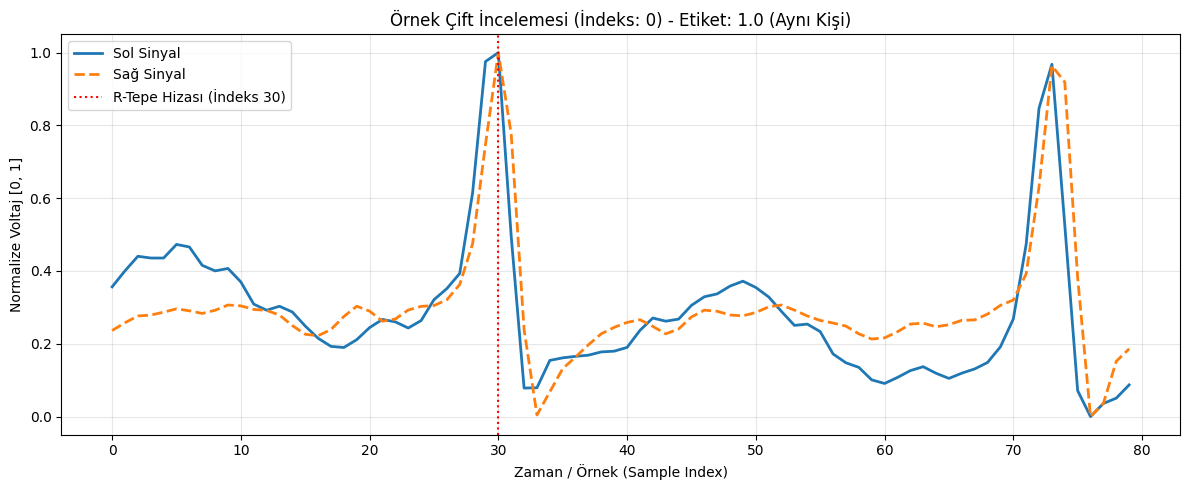

In [18]:
# 1. Drive'a kaydettiğimiz dosyaları sıfırdan geri yüklüyoruz
print("x")
X_left_loaded = np.load(os.path.join(OUTPUT_DIR, "X_left.npy"))
X_right_loaded = np.load(os.path.join(OUTPUT_DIR, "X_right.npy"))
y_loaded = np.load(os.path.join(OUTPUT_DIR, "y.npy"))

print("=== VERİ DOĞRULAMA RAPORU ===")
print(f"Yüklenen X_left Şekli : {X_left_loaded.shape}")
print(f"Yüklenen X_right Şekli: {X_right_loaded.shape}")
print(f"Yüklenen y (Etiket) Şekli: {y_loaded.shape}")

# 2. Rastgele bir indeks seçip sinyalleri görselleştirelim
random_idx = np.random.randint(0, len(y_loaded))
sample_left = X_left_loaded[random_idx]
sample_right = X_right_loaded[random_idx]
label = y_loaded[random_idx]

# Grafik çizimi
plt.figure(figsize=(12, 5))

plt.plot(sample_left, label='Sol Sinyal', color='#1f77b4', linewidth=2)
plt.plot(sample_right, label='Sağ Sinyal', color='#ff7f0e', linewidth=2, linestyle='--')

# R-tepesi hizasını (30. indeks) göstermek için dikey çizgi
plt.axvline(x=30, color='red', linestyle=':', label='R-Tepe Hizası (İndeks 30)')

plt.title(f"Örnek Çift İncelemesi (İndeks: {random_idx}) - Etiket: {label} ({'Aynı Kişi' if label == 1.0 else 'Farklı Kişi'})")
plt.xlabel("Zaman / Örnek (Sample Index)")
plt.ylabel("Normalize Voltaj [0, 1]")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()